# 21. V/Phi scalar CLN with compatible high-order recovery

The global physical A-T vector solve is replaced in this route. Every stage uses a hybrid-mixed scalar Poisson problem followed by element-local curl reconstruction. Original A-T runs separately as a reference; explicit guards forbid calling its solver or condensed vector fallback from the scalar recursion.

This notebook displays saved native results. See the [equations, boundary conditions, source comparison and reproduction](SCALAR_CLN.md), [previous recovery-only integration](20_compatible_element_recovery.ipynb), and [A-T accuracy scope](17_formulation_ranking.ipynb).

The scalar PDE construction follows [Bíró and Köster's accessible Compumag manuscript](https://www.compumag.org/Proceedings/2021_Cancun/www.conftool.pro/compumag2021/index.php/OA1-2-299ecbe.pdf?filename=OA1-2-299.pdf&form_id=299&form_version=final&ismobile=false&page=downloadPaper). Its nodal discretization is replaced by a compatible hybrid-mixed realization; this is not a claimed reproduction of unavailable journal implementation details.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == 'docs': root = root.parent
study = json.loads((root/'docs/data/scalar_cln_study.json').read_text())
control = json.loads((root/'docs/data/scalar_nodal_control.json').read_text())
assert study['complete'] and control['complete']
print('Native runtime:', study['runtime'])
print(study['timing_protocol'])

Native runtime: {'host': 'intel11', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'numpy': '2.5.2', 'radia': '5.2.3', 'threads': 4, 'blas_pools': [{'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.34.0.0', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'blas', 'internal_api': 'mkl', 'num_threads': 1, 'prefix': 'mkl_rt', 'version': '2026.1-Product', 'threading_layer': 'intel'}, {'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.30', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'openmp', 'internal_api': 'openmp', 'num_threads': 4, 'prefix': 'libiomp', 'version': None}]}
First observed plus three warmed complete runs per route, alternating order; setup, scalar/local recovery and all residual checks included; mesh and cross-comparison excluded


## Scalar equations, compatible flux

For a particular field P, solve the mixed weak form of q = P - grad(u), div(q) = 0. A discontinuous HDiv flux, a cell scalar and a scalar facet trace are used. NGSolve eliminates the flux and cell scalar separately on each element. The only globally factored unknown is the scalar facet potential. At HCurl order p, the spaces are HDiv(p-1), L2(p-2), and scalar Facet(p-1).

The initial electric lift is e_z. Magnetic increments use P = R*T and zero normal B on the full boundary. Electric increments use P = -A/L and zero scalar correction on the full boundary, matching the original wire's A-T conditions. The reconstructed cumulative T/A supply subsequent scalar right-hand sides. R and L are computed from physical current and magnetic-energy integrals.

The ordinary nodal Phi control below solves its scalar equation accurately but produces a flux outside the required discrete curl image. Local reconstruction must reject it. The projection lower bound measures missing local curl content even before shared-boundary constraints are imposed.

In [2]:
print('geometry  p   nodal equation residual   local curl error lower bound   nodal/hybrid B difference')
for r in control['cases']:
    print(r['curve'],r['order'],f"{r['scalar_residual']:.3e}",f"{r['element_projection_lower_bound']:.3e}",f"{r['nodal_hybrid_field_difference']:.3e}")
assert all(r['strict_recovery_failure']['reason'] for r in control['cases'])
print('All four incompatible nodal targets rejected; no vector fallback.')

geometry  p   nodal equation residual   local curl error lower bound   nodal/hybrid B difference
1 2 7.388e-15 1.351e-02 3.354e-02
1 3 1.539e-14 1.127e-02 1.708e-02
3 2 6.858e-15 2.598e-03 3.579e-03
3 3 1.320e-14 2.080e-04 2.238e-04
All four incompatible nodal targets rejected; no vector fallback.


## Full recursion and physical equation checks

Four cohorts cover p=2/3/4 at 3 mm plus p=3 at 2 mm, curved geometry order 3 and three complete CLN stages. All routes share each cohort's exact mesh and quadrature. Seven coefficients and seven volume vector fields are compared. The scalar route has no reference field or coefficient as input.

For a contractible domain, the constrained divergence-free HDiv space is the corresponding discrete curl image. Integration by parts therefore makes the mixed scalar projection satisfy the original A-T physical weak equations. This is checked numerically at every stage, in addition to an independent matrix-free uncondensed scalar-system residual. Potential gauge coefficients are not compared.

The scalar solve and recovered original physical equations must each satisfy residual <= 1e-6. Local curl fit is requested at 1e-10, integrated recovery error <= 1e-8, and full-run coefficient/volume-field parity <= 1e-6. Energies and 78-point physical vector samples provide additional portable checks.

In [3]:
print('p h[mm]  max coefficient difference  max volume field difference  max physical residual  max scalar residual')
for c in study['cohorts']:
    comp=[r for r in c['comparisons'] if r['route']=='scalar-VPhi']
    runs=[r for r in c['repeats'] if r['route']=='scalar-VPhi']
    ce=max(abs(v) for r in comp for v in r['relative_coefficients'])
    fe=max(v for r in comp for v in r['volume_relative_field_errors'])
    re=max(s['recovered_original_residual'] for r in runs for s in r['solves'])
    se=max(s['original_scalar_residual'] for r in runs for s in r['solves'])
    print(c['order'],c['maxh']*1000,*[f'{x:.3e}' for x in (ce,fe,re,se)])
print('Complete runs:',sum(len(c['repeats']) for c in study['cohorts']))
print('Scalar solves/local recoveries:',sum(len(r['solves']) for c in study['cohorts'] for r in c['repeats'] if r['route']=='scalar-VPhi'))
assert all(r['global_vector_solves']==0 and all(s['global_vector_solves']==0 for s in r['solves']) for c in study['cohorts'] for r in c['repeats'] if r['route']=='scalar-VPhi')
print('All recorded scalar routes: zero global vector solves')

p h[mm]  max coefficient difference  max volume field difference  max physical residual  max scalar residual
2 3.0 1.280e-10 4.173e-09 2.471e-10 2.931e-15
3 3.0 1.286e-10 4.304e-09 2.471e-10 8.789e-15
3 2.0 9.509e-11 6.518e-09 4.221e-10 6.794e-15
4 3.0 1.278e-10 4.465e-09 2.473e-10 1.548e-14
Complete runs: 48
Scalar solves/local recoveries: 112
All recorded scalar routes: zero global vector solves


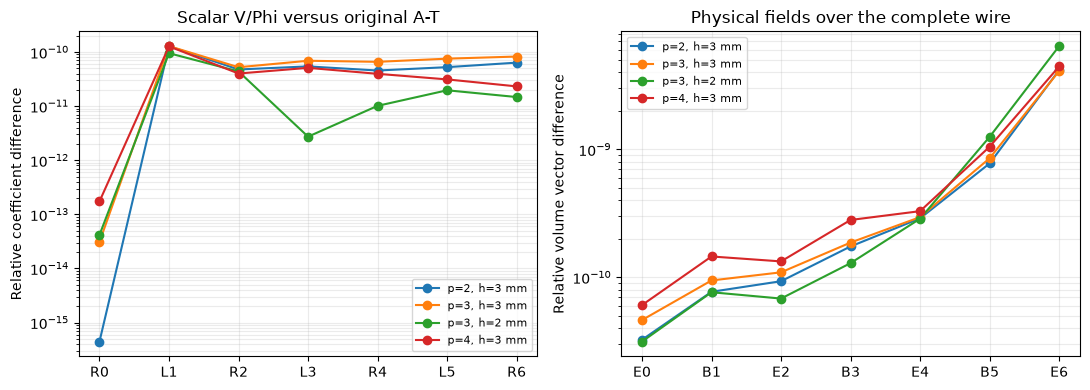

In [4]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for c in study['cohorts']:
    comp=next(r for r in c['comparisons'] if r['route']=='scalar-VPhi' and r['repeat']==0)
    label=f"p={c['order']}, h={c['maxh']*1000:g} mm"
    axes[0].semilogy(np.arange(7),np.maximum(abs(np.asarray(comp['relative_coefficients'])),1e-16),'-o',label=label)
    axes[1].semilogy(np.arange(7),comp['volume_relative_field_errors'],'-o',label=label)
axes[0].set(xticks=range(7),xticklabels=['R0','L1','R2','L3','R4','L5','R6'],ylabel='Relative coefficient difference',title='Scalar V/Phi versus original A-T')
axes[1].set(xticks=range(7),xticklabels=['E0','B1','E2','B3','E4','B5','E6'],ylabel='Relative volume vector difference',title='Physical fields over the complete wire')
for ax in axes:ax.legend(fontsize=8);ax.grid(True,which='both',alpha=.25)
fig.tight_layout();plt.show()

## Complete-run time, including reconstruction and checks

Timing uses NGSolve four threads and one BLAS thread. Each route has one first observed run and three subsequent warmed runs, with alternating route order. Setup, scalar/global solves, local reconstruction and residual checks are included. Mesh generation and cross-route comparison are excluded. Bars show warmed medians; error bars span the three observations. A preliminary run with four BLAS threads showed timing variability and was stopped; its partial numerical data, sources and logs are retained as operational diagnostics.

Removing the global vector solve does not itself establish acceleration. The local inverse remains iterative, and the scalar facet problem can have more unknowns than an optimized vector trace problem.

original median seconds: [np.float64(0.7693), np.float64(2.0321), np.float64(6.8929), np.float64(5.7603)]
condensed median seconds: [np.float64(0.6218), np.float64(1.5404), np.float64(4.595), np.float64(3.2115)]
scalar-VPhi median seconds: [np.float64(5.5842), np.float64(10.4418), np.float64(59.0211), np.float64(21.2989)]


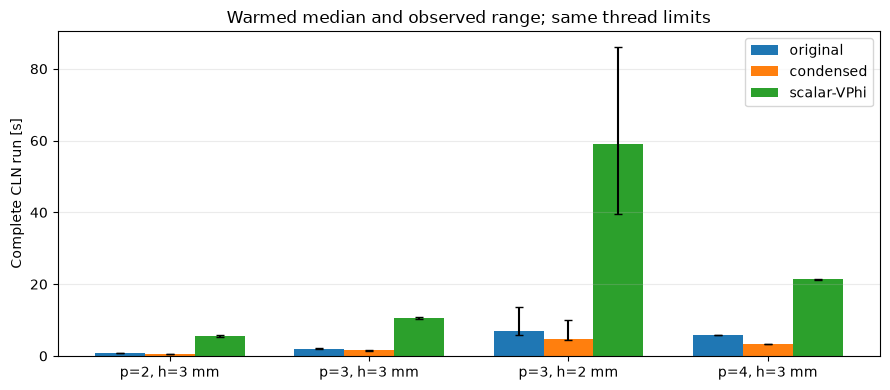

p 2 h 3.0 global scalar V/Phi DOFs: 2622 3497 local sweep counts: [200, 110, 200, 100, 180, 90, 180]
Matched A-T vector trace T/A DOFs: 3162 2140
p 3 h 3.0 global scalar V/Phi DOFs: 5244 6995 local sweep counts: [200, 110, 200, 100, 180, 80, 170]
Matched A-T vector trace T/A DOFs: 6660 4762
p 3 h 2.0 global scalar V/Phi DOFs: 16134 20105 local sweep counts: [360, 230, 350, 220, 320, 200, 290]
Matched A-T vector trace T/A DOFs: 19040 14737
p 4 h 3.0 global scalar V/Phi DOFs: 8740 11659 local sweep counts: [200, 110, 200, 100, 180, 90, 180]
Matched A-T vector trace T/A DOFs: 11324 8258


In [5]:
routes=['original','condensed','scalar-VPhi']
x=np.arange(len(study['cohorts']))
fig,ax=plt.subplots(figsize=(9,4))
labels=[f"p={c['order']}, h={c['maxh']*1000:g} mm" for c in study['cohorts']]
for j,route in enumerate(routes):
    samples=[np.asarray([r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']>0]) for c in study['cohorts']]
    median=np.array([np.median(s) for s in samples])
    err=np.array([[m-s.min() for m,s in zip(median,samples)],[s.max()-m for m,s in zip(median,samples)]])
    ax.bar(x+(j-1)*.25,median,.25,label=route,yerr=err,capsize=3)
    print(route,'median seconds:',[round(v,4) for v in median])
ax.set(xticks=x,xticklabels=labels,ylabel='Complete CLN run [s]',title='Warmed median and observed range; same thread limits')
ax.legend();ax.grid(True,axis='y',alpha=.25);fig.tight_layout();plt.show()
for c in study['cohorts']:
    r=next(r for r in c['repeats'] if r['route']=='scalar-VPhi' and r['repeat']==0)
    print('p',c['order'],'h',c['maxh']*1000,'global scalar V/Phi DOFs:',r['solves'][0]['global_scalar_dofs'],r['solves'][1]['global_scalar_dofs'],'local sweep counts:',[s['sweeps'] for s in r['solves']])
    ref=next(v for v in c['repeats'] if v['route']=='condensed' and v['repeat']==0)
    print('Matched A-T vector trace T/A DOFs:',ref['solves'][0]['trace_free'],ref['solves'][1]['trace_free'])

The scalar-global route is a complete replacement in these matched zero-shift, constant-material internal-wire cases. It does not establish air coupling, variable coefficients, nontrivial topology, positive shifts or nonlinear validity. It should not inherit a speedup claim from the published paper's different model, mesh, implementation or discretization.

The [portable gate](../validation/validate_scalar_cln.py) verifies source hashes, all stage residuals, scalar factor dimensions, absence of recorded vector solves, energies, coefficients, vector samples, coverage and incompatible nodal controls. Eight deliberately corrupted datasets must reject. Runtime guards additionally forbid the reference A-T solver and vector trace constructor during actual scalar execution. These additions are Codex self-review, without a new external scientific acceptance claim.